# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** Apple MPS, в 6.4 - CPU. Бонусы 6.2-6.5.

RuBERT-tiny2 (MIT) - https://huggingface.co/cointegrated/rubert-tiny2 \
WikiNEuRal (CC BY-NC-SA 4.0) - https://huggingface.co/datasets/Babelscape/wikineural \
RuBERT-tiny (MIT) - https://huggingface.co/cointegrated/rubert-tiny

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

W1122 20:09:58.555000 34827 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


torch 2.15.0, transformers 5.22.1, datasets 5.1.0
CUDA available: False


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

mps mps


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else 12000
N_EVAL = 500 if FAST_MODE else 2000
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
TOKENIZER_KWARGS = {}
MODEL_KWARGS = {'use_safetensors': True, 'attn_implementation': 'eager' if device.type == 'mps' else 'sdpa'}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** RuBERT-tiny2 (MIT, 29,4 млн параметров) подходит для русскоязычного NER. Его дообучали на MLM, NLI и приближении эмбеддингов LaBSE. RuBERT-base-cased (180 млн параметров) обучался на русской Википедии и новостях. В бонусе 6.2 RuBERT-tiny2 дал F1 0,810 против 0,778 у RuBERT-tiny, а инференс на 32 предложениях занял 7,5 против 8,4 мс. Ревизия фиксирует веса, конфиг и токенизатор.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS, **MODEL_KWARGS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    base = model.base_model

    def count(module):
        return sum(parameter.numel() for parameter in module.parameters())

    embeddings = count(base.embeddings)
    layers = [count(layer) for layer in base.encoder.layer]
    encoder = sum(layers)
    head = count(model.classifier)
    other = count(model) - embeddings - encoder - head
    return dict(embeddings=embeddings, encoder=encoder, head=head, other=other, layers=layers)

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
# ваш код
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)

print('input_ids:', tuple(enc['input_ids'].shape))
print('attention_mask:', tuple(enc['attention_mask'].shape))
print('hidden_states:', [tuple(state.shape) for state in out.hidden_states])
print('logits:', tuple(out.logits.shape))

input_ids: (2, 11)
attention_mask: (2, 11)
hidden_states: [(2, 11, 312), (2, 11, 312), (2, 11, 312), (2, 11, 312)]
logits: (2, 11, 7)


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 4.7 ms на mps


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** Входы (2, 11) - эмбеддинги и три слоя (2, 11, 312) - логиты (2, 11, 7). Сабворды, спецтокены и паддинг увеличивают длину до 11. Эмбеддинги занимают 92,1% параметров из-за словаря на 83 828 токенов. В энкодере каждый токен учитывает другие токены предложения. Голова отдельно оценивает теги для каждого токена.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
example = dict(tokens=['Анна', 'живет', 'в', 'Москве'],
               ner_tags=['B-PER', 'O', 'O', 'B-LOC'])
print(list(zip(example['tokens'], example['ner_tags'])))

[('Анна', 'B-PER'), ('живет', 'O'), ('в', 'O'), ('Москве', 'B-LOC')]


In [13]:
DATASET_ID, DATASET_CONFIG = 'Babelscape/wikineural', 'ru'
DATASET_REVISION = '74c9b9dca034bb1606a6769457983904bd976803'
dataset_root = f'hf://datasets/{DATASET_ID}@{DATASET_REVISION}/data'
split_files = {'train': 'train_ru', 'validation': 'val_ru', 'test': 'test_ru'}
raw = load_dataset('parquet', data_files={
    split: f'{dataset_root}/{name}-00000-of-00001.parquet'
    for split, name in split_files.items()
}).select_columns(['tokens', 'ner_tags'])
LABEL_NAMES = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']

In [14]:
# ваша статистика: сущности по типам и сплитам, длины спанов в словах, длины предложений
# ваш код
def bio_to_spans(tags):
    spans = []
    start, entity_type = 0, None
    for index, tag in enumerate([*tags, 'O']):
        prefix, _, kind = tag.partition('-')
        if prefix == 'I' and entity_type == kind:
            continue
        if entity_type is not None:
            spans.append((start, index, entity_type))
        start, entity_type = index, None if tag == 'O' else kind
    return spans


def describe_dataset(dataset):
    stats = {}
    for split, rows in dataset.items():
        tag_counts = collections.Counter()
        span_lengths = collections.Counter()
        sentence_lengths = []
        for row in rows:
            words, ids = row['tokens'], row['ner_tags']
            assert len(words) == len(ids)
            sentence_lengths.append(len(words))
            for start, end, kind in bio_to_spans([LABEL_NAMES[i] for i in ids]):
                tag_counts[kind] += 1
                span_lengths[end - start] += 1
        stats[split] = dict(sentences=len(rows), entities=dict(sorted(tag_counts.items())),
                            span_lengths=dict(sorted(span_lengths.items())),
                            word_count_percentiles=np.percentile(sentence_lengths, [0, 50, 100]).tolist())
    return stats


dataset_stats = describe_dataset(raw)
for split, stats in dataset_stats.items():
    print(f'{split}: {stats["sentences"]} предложений')
    print('По типам:', stats['entities'])
    print('Длины спанов (слова → число спанов):', stats['span_lengths'])
    print('Длины предложений (мин, медиана, макс):', stats['word_count_percentiles'])

train: 92320 предложений
По типам: {'LOC': 71090, 'MISC': 23594, 'ORG': 20236, 'PER': 33282}
Длины спанов (слова → число спанов): {1: 116812, 2: 21879, 3: 6566, 4: 1737, 5: 599, 6: 294, 7: 147, 8: 75, 9: 54, 10: 21, 11: 10, 12: 3, 13: 2, 17: 1, 18: 1, 24: 1}
Длины предложений (мин, медиана, макс): [2.0, 17.0, 256.0]
validation: 11540 предложений
По типам: {'LOC': 8851, 'MISC': 2642, 'ORG': 2710, 'PER': 4007}
Длины спанов (слова → число спанов): {1: 14212, 2: 2789, 3: 858, 4: 210, 5: 73, 6: 35, 7: 20, 8: 10, 9: 2, 10: 1}
Длины предложений (мин, медиана, макс): [2.0, 17.0, 107.0]
test: 11580 предложений
По типам: {'LOC': 8596, 'MISC': 2962, 'ORG': 3051, 'PER': 3489}
Длины спанов (слова → число спанов): {1: 13829, 2: 2899, 3: 941, 4: 239, 5: 92, 6: 50, 7: 27, 8: 10, 9: 4, 10: 2, 11: 4, 13: 1}
Длины предложений (мин, медиана, макс): [2.0, 17.0, 124.0]


**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** WikiNEuRal - русская Википедия с автоматической разметкой CC BY-NC-SA 4.0.
PER - люди, ORG - организации, LOC - места, MISC - прочие сущности.
train - 92 320 предложений, PER 33 282, ORG 20 236, LOC 71 090, MISC 23 594.
validation - 11 540 предложений, PER 4 007, ORG 2 710, LOC 8 851, MISC 2 642.
test - 11 580 предложений, PER 3 489, ORG 3 051, LOC 8 596, MISC 2 962.

ORG реже всего в train. Там 78,8% спанов состоят из одного слова, медиана длины предложения - 17 слов. Длинных спанов мало, автоматическая разметка может пропускать сущности. Для прогона выбрал 12 000 / 2 000 / 2 000 предложений, фиксировал seed.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    # ваш код
    tags = ['O'] * n_words
    for start, end, kind in spans:
        tags[start:end] = [f'B-{kind}'] + [f'I-{kind}'] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    # ваш код
    labels = []
    seen = set()
    for word_id in word_ids:
        if word_id is None:
            labels.append(-100)
            continue
        tag = word_labels[word_id]
        if word_id in seen:
            tag = -100 if b_to_i is None else b_to_i.get(tag, tag)
        labels.append(tag)
        seen.add(word_id)
    return labels

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
# если датасет не в формате «слова + BIO»: конвертация в контракт из 2.1
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
# ваш код
data_dir = Path('data')
data_dir.mkdir(exist_ok=True)
roundtrip = {}

for split, rows in raw.items():
    span_file = data_dir / f'{split}_spans.jsonl'
    with span_file.open('w', encoding='utf-8') as output:
        for row in rows:
            tags = [LABEL_NAMES[i] for i in row['ner_tags']]
            output.write(json.dumps(bio_to_spans(tags), ensure_ascii=False) + '\n')
    changed = 0
    with span_file.open(encoding='utf-8') as saved:
        for line, row in zip(saved, rows, strict=True):
            spans = [tuple(span) for span in json.loads(line)]
            tags = [LABEL_NAMES[i] for i in row['ner_tags']]
            restored = spans_to_bio(spans, len(tags))
            assert bio_to_spans(restored) == bio_to_spans(tags)
            changed += restored != tags
    roundtrip[split] = changed
    print(f'{split}: проверено {len(rows):} предложений, изменился BIO в {changed:}')

train: проверено 92320 предложений, изменился BIO в 3210
validation: проверено 11540 предложений, изменился BIO в 393


test: проверено 11580 предложений, изменился BIO в 464


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 12000
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 2000
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']


train: проверено 11990 предложений, обрезано по MAX_LENGTH 10, слов без сабвордов или за обрезкой 178
[CLS]            None  -100
Работы              0  O
по                  1  O
строительству       2  O
первоначальной      3  O
инфраструктуры      4  O
аэропорта           5  O
начались            6  O
в                   7  O
1937                8  O
году                9  O
на                 10  O
месте              11  O
девяти             12  O
сельскохозяйственных   13  O
угодий             14  O
,                  15  O
выкуп              16  O
##ленных           16  -100
муниципальным      17  O
комитетом          18  O
Торонто            19  B-LOC
у                  20  O
частных            21  O
владельцев         22  O
.                  23  O
[SEP]            None  -100


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Метка первого сабворда даёт один вклад в loss на слово. Метка -100 исключает остальные позиции из loss. В train 10 предложений достигли лимита 128 токенов, 178 слов осталось без метки. Для этих слов модель ставит O. Если такое слово входило в сущность, модель может пропустить её целиком или найти только часть. После записи спанов и чтения обратно теги изменились в 3 210 предложениях train, 393 validation и 464 test. Границы и типы сущностей сохранились.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id, **MODEL_KWARGS)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    # ваш код
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list, strict=True):
        for word, tag in zip(words, tags, strict=True):
            counts[word][tag] += 1
    return {word: tags.most_common(1)[0][0] for word, tags in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    # ваш код
    return [tagger.get(word, 'O') for word in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_rows = data['train']
train_gold = [[LABEL_NAMES[i] for i in tags] for tags in train_rows['ner_tags']]
tagger = fit_majority_tagger(train_rows['tokens'], train_gold)
majority_pred = [predict_majority(tagger, words) for words in val_tokens]

set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
del random_model

baseline = {
    'majority': entity_scores(val_gold, majority_pred),
    'random_head': entity_scores(val_gold, random_pred),
}
random_tag_counts = collections.Counter(tag for sentence in random_pred for tag in sentence)
entity_words = [word for words, tags in zip(val_tokens, val_gold)
                for word, tag in zip(words, tags) if tag != 'O']
entity_word_coverage = sum(word in tagger for word in entity_words) / max(1, len(entity_words))
print(f"Словарь: F1 {baseline['majority']['f1_micro']:.3f}")
print(f"Случайная голова: F1 {baseline['random_head']['f1_micro']:.3f}")
print('Случайная голова, частоты тегов:', dict(random_tag_counts))
print(f'Доля знакомых слов среди слов сущностей на validation: {entity_word_coverage:.1%}')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Словарь: F1 0.446
Случайная голова: F1 0.029
Случайная голова, частоты тегов: {'B-PER': 6629, 'I-PER': 9255, 'O': 7840, 'I-LOC': 2129, 'B-ORG': 1949, 'I-ORG': 2459, 'B-LOC': 3496, 'I-MISC': 2763, 'B-MISC': 978}
Доля знакомых слов среди слов сущностей на validation: 53.1%


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** F1 словаря - 0,446. Только 53,1% слов из сущностей validation встречались в train, а словарь игнорирует контекст. Случайная голова чаще всего выдавала I-PER и получила F1 0,029, потому что её веса ещё не обучены на BIO.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 2e-4          # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    # ваш код
    model.base_model.requires_grad_(not freeze_encoder)
    steps = math.ceil(len(train_ds) / batch_size) * epochs
    interval = max(1, steps // 10)
    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=epochs,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        learning_rate=lr,
        warmup_steps=math.ceil(steps * 0.05),
        weight_decay=0.01,
        fp16=device.type == 'cuda',
        eval_strategy='steps',
        eval_steps=interval,
        logging_steps=interval,
        save_strategy='no',
        report_to='none',
        seed=SEED,
        disable_tqdm=True,
    )
    collator = DataCollatorForTokenClassification(tok, pad_to_multiple_of=8 if device.type == 'cuda' else None)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                        data_collator=collator, processing_class=tok)
    start = time.perf_counter()
    trainer.train()
    return trainer.state.log_history, time.perf_counter() - start

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

/Users/igordyslevski/Study/DLCourse/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': '0.5382', 'grad_norm': '0.797', 'learning_rate': '0.0001899', 'epoch': '0.2987'}


{'eval_loss': '0.1562', 'eval_runtime': '0.4286', 'eval_samples_per_second': '4666', 'eval_steps_per_second': '147', 'epoch': '0.2987'}


{'loss': '0.1267', 'grad_norm': '0.8878', 'learning_rate': '0.0001689', 'epoch': '0.5973'}


{'eval_loss': '0.1089', 'eval_runtime': '0.4168', 'eval_samples_per_second': '4798', 'eval_steps_per_second': '151.2', 'epoch': '0.5973'}


... (13 outputs left out)

{'eval_loss': '0.08292', 'eval_runtime': '0.462', 'eval_samples_per_second': '4329', 'eval_steps_per_second': '136.4', 'epoch': '2.688'}


{'loss': '0.03095', 'grad_norm': '1.565', 'learning_rate': '1.124e-06', 'epoch': '2.987'}


{'eval_loss': '0.08299', 'eval_runtime': '0.4209', 'eval_samples_per_second': '4751', 'eval_steps_per_second': '149.7', 'epoch': '2.987'}


{'eval_loss': '0.08298', 'eval_runtime': '0.437', 'eval_samples_per_second': '4577', 'eval_steps_per_second': '144.2', 'epoch': '3'}
{'train_runtime': '34.85', 'train_samples_per_second': '1033', 'train_steps_per_second': '32.28', 'train_loss': '0.1095', 'epoch': '3'}
обучение: 34.9 c на mps, 12000 предложений, 3 эпох(а)


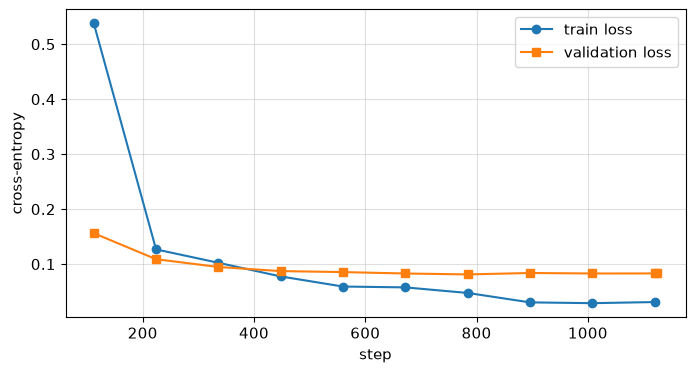

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** Для маленького энкодера выбрал LR 2e-4, батч 32 и weight decay 0,01. За три эпохи train loss снизился с 0,538 до 0,031, validation loss - с 0,156 до 0,083. Минимум на validation - 0,081. После минимума loss на validation немного вырос. Больше эпох, скорее всего, не нужно. Обучение заняло 34,9 с на MPS.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    # ваш код
    true_positive = gold_positive = pred_positive = 0
    for gold_tags, pred_tags in zip(gold, pred, strict=True):
        for expected, predicted in zip(gold_tags, pred_tags, strict=True):
            gold_positive += expected != 'O'
            pred_positive += predicted != 'O'
            true_positive += predicted != 'O' and predicted == expected
    total_positive = gold_positive + pred_positive
    return 2 * true_positive / total_positive if total_positive else 0.0

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

def evaluate_split(name, gold_labels, predicted_labels):
    report = classification_report(gold_labels, predicted_labels, output_dict=True, zero_division=0)
    scores = entity_scores(gold_labels, predicted_labels)
    scores['token_f1'] = token_f1(gold_labels, predicted_labels)
    scores['per_type'] = {kind: dict(report.get(kind, {
        'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 0,
    })) for kind in ENTITY_TYPES}
    print(f'{name}:')
    print(classification_report(gold_labels, predicted_labels, digits=4, zero_division=0))
    print(f'F1 по словам: {scores["token_f1"]:.4f}')
    return scores


val_pred = predict_word_tags(model, val_tokens)
validation = evaluate_split('validation', val_gold, val_pred)
test_rows = data['test']
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in test_rows['ner_tags']]
test_pred = predict_word_tags(model, test_rows['tokens'])
final = evaluate_split('test', test_gold, test_pred)

validation:
              precision    recall  f1-score   support

         LOC     0.8716    0.8990    0.8851      1525
        MISC     0.6462    0.6616    0.6538       461
         ORG     0.6730    0.6875    0.6802       464
         PER     0.8157    0.8543    0.8345       741

   micro avg     0.7976    0.8236    0.8104      3191
   macro avg     0.7516    0.7756    0.7634      3191
weighted avg     0.7972    0.8236    0.8101      3191

F1 по словам: 0.8326


test:
              precision    recall  f1-score   support

         LOC     0.8810    0.9080    0.8943      1566
        MISC     0.6542    0.6796    0.6667       490
         ORG     0.6523    0.6882    0.6698       526
         PER     0.8165    0.8551    0.8354       635

   micro avg     0.7957    0.8269    0.8110      3217
   macro avg     0.7510    0.7827    0.7665      3217
weighted avg     0.7964    0.8269    0.8113      3217

F1 по словам: 0.8292


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** Хуже всего MISC (F1 0,667): класс разнородный, на test 490 спанов против 1 566 у LOC. Micro F1 0,811 сильнее зависит от частых типов, macro F1 0,767 взвешивает типы одинаково. F1 по словам выше (0,829) за счёт частичных совпадений. Для NER важнее F1 по целым спанам: нужны обе границы и тип.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    # ваш код
    def overlap(first, second):
        return max(0, min(first[1], second[1]) - max(first[0], second[0]))

    results = []
    for gold in gold_spans:
        overlapping = [pred for pred in pred_spans if overlap(gold, pred)]
        same_type = [pred for pred in overlapping if pred[2] == gold[2]]
        if gold in same_type:
            results.append(('correct', gold, gold))
        elif same_type:
            results.append(('boundary', gold, max(same_type, key=lambda pred: overlap(gold, pred))))
        elif overlapping:
            results.append(('type', gold, max(overlapping, key=lambda pred: overlap(gold, pred))))
        else:
            results.append(('missed', gold, None))
    results.extend(('spurious', None, pred) for pred in pred_spans
                    if not any(overlap(gold, pred) for gold in gold_spans))
    return results

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

def format_span(words, span):
    if span is None:
        return 'нет'
    start, end, kind = span
    return f'{" ".join(words[start:end])} [{kind}, {start}:{end}]'


counts = collections.Counter()
error_examples = collections.defaultdict(list)
for index, (words, gold_tags, pred_tags) in enumerate(zip(val_tokens, val_gold, val_pred, strict=True)):
    for category, gold_span, pred_span in categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags)):
        counts[category] += 1
        if category != 'correct' and len(error_examples[category]) < 2:
            if not any(example['index'] == index for example in error_examples[category]):
                error_examples[category].append(dict(index=index, sentence=' '.join(words),
                                                     gold=format_span(words, gold_span),
                                                     pred=format_span(words, pred_span)))

errors = {category: counts[category] for category in ERROR_CATEGORIES}
n_errors = sum(count for category, count in errors.items() if category != 'correct')
print('Точные совпадения:', errors['correct'])
for category in ERROR_CATEGORIES[1:]:
    print(f'{category}: {errors[category]} ({errors[category] / max(1, n_errors):.1%} ошибок)')
    limit = 2 if category == 'type' else 1
    for example in error_examples[category][:limit]:
        print(f"  {example['sentence']}\n  gold: {example['gold']} | pred: {example['pred']}")

Точные совпадения: 2628
boundary: 170 (24.6% ошибок)
  Брокхауз стал профессором в университете Мак-Мастера в Канаде , где и оставался до пенсии в 1984 г .
  gold: университете Мак-Мастера [LOC, 4:6] | pred: Мак-Мастера [LOC, 5:6]
type: 305 (44.2% ошибок)
  Согласно предъявленному в дальнейшем обвинению в пиратстве , первое разбойное нападение Кидда было совершено недалеко от Тулеара , на юго-западе Мадагаскара в конце 1696 года , куда на самом деле « Приключение » после долгого путешествия вдоль западного побережья Африки смогло прийти не ранее 27 января 1697 года .
  gold: Кидда [PER, 11:12] | pred: Кидда [LOC, 11:12]
  Хотя резиденция епископа Содора находилась на Мэне , его деятельность способствовала развитию церковной жизни на всех Гебридских островах .
  gold: Содора [PER, 3:4] | pred: Содора [LOC, 3:4]
missed: 88 (12.8% ошибок)
  В игре " RoboCop versus The Terminator " приобретает цель уничтожить « Скайнет » .
  gold: Скайнет [MISC, 12:13] | pred: нет
spurious: 127 (18.4% ошиб

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** Чаще всего ошибался тип (305 из 690, 44,2%): фамилии «Кидда» и «Содора» стали LOC. В ошибке границы «университете Мак-Мастера» сократилось до «Мак-Мастера», а «Скайнет» пропущен целиком. У «МПЛА» вероятен пропуск в разметке. Для уменьшения ошибок типа добавил бы примеры редких фамилий в косвенных падежах.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'
set_seed(SEED)
ablation_model = make_model()
ablation_history, ablation_seconds = train_ner(
    ablation_model, tokenized['train'], tokenized['validation'], freeze_encoder=True,
    out_dir='runs/freeze',
)
ablation_pred = predict_word_tags(ablation_model, val_tokens)

def trainable_params(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

ablation = {
    'setting': ABLATION,
    'split': 'validation',
    'full': dict(**entity_scores(val_gold, val_pred), seconds=train_seconds,
                 trainable_params=trainable_params(model)),
    'freeze': dict(**entity_scores(val_gold, ablation_pred), seconds=ablation_seconds,
                   trainable_params=trainable_params(ablation_model)),
}
RUN_TIMES['train_freeze_sec'] = ablation_seconds
for name, label in [('full', 'Полное обучение'), ('freeze', 'Заморозка')]:
    scores = ablation[name]
    print(f"{label}: F1 {scores['f1_micro']:.3f}, {scores['seconds']:.1f} с, "
          f"параметров {scores['trainable_params']}")

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '1.47', 'grad_norm': '1.814', 'learning_rate': '0.0001899', 'epoch': '0.2987'}


{'eval_loss': '0.7033', 'eval_runtime': '0.4049', 'eval_samples_per_second': '4939', 'eval_steps_per_second': '155.6', 'epoch': '0.2987'}


{'loss': '0.4884', 'grad_norm': '0.4327', 'learning_rate': '0.0001689', 'epoch': '0.5973'}


{'eval_loss': '0.3982', 'eval_runtime': '0.3891', 'eval_samples_per_second': '5140', 'eval_steps_per_second': '161.9', 'epoch': '0.5973'}


{'loss': '0.3583', 'grad_norm': '0.3976', 'learning_rate': '0.0001479', 'epoch': '0.896'}


... (13 outputs left out)

{'loss': '0.2616', 'grad_norm': '0.2579', 'learning_rate': '1.124e-06', 'epoch': '2.987'}


{'eval_loss': '0.2484', 'eval_runtime': '0.4943', 'eval_samples_per_second': '4047', 'eval_steps_per_second': '127.5', 'epoch': '2.987'}


{'eval_loss': '0.2484', 'eval_runtime': '0.4806', 'eval_samples_per_second': '4161', 'eval_steps_per_second': '131.1', 'epoch': '3'}
{'train_runtime': '14.68', 'train_samples_per_second': '2452', 'train_steps_per_second': '76.62', 'train_loss': '0.4265', 'epoch': '3'}


Полное обучение: F1 0.810, 34.9 с, параметров 29098929
Заморозка: F1 0.503, 14.9 с, параметров 2817


**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** Заморозка сократила время с 34,9 до 14,9 с и число обучаемых параметров с 29 098 929 до 2 817. F1 упал с 0,810 до 0,503: фиксированные признаки хуже подходят под эту разметку. Повторил бы сравнение с несколькими seed.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** Дообучение подняло F1 на validation с 0,446 у словаря до 0,810. Случайная голова дала 0,029. На test F1 по спанам - 0,811. Заморозка дала 0,503 на validation. Ограничения - автоматическая разметка, подвыборки и один seed. Дальше проверил бы модель на ручной разметке.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print('final F1 micro', round(final['f1_micro'], 4))

final F1 micro 0.811


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** 

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
def batch_latency(predict, repeats=20):
    for _ in range(5):
        predict()
    start = time.perf_counter()
    for _ in range(repeats):
        predict()
    return 1000 * (time.perf_counter() - start) / repeats


if '6.2' in BONUS_TASKS:
    # ваш код
    alt_id = 'cointegrated/rubert-tiny'
    alt_revision = '5441c5ea8026d4f6d7505ec004845409f1259fb1'
    alt_tokenizer = AutoTokenizer.from_pretrained(alt_id, revision=alt_revision)
    assert alt_tokenizer.is_fast
    alt_data = data.map(tokenize_and_align, batched=True, fn_kwargs={'tok': alt_tokenizer},
                        remove_columns=data['train'].column_names)
    set_seed(SEED)
    alt_model = make_model(alt_id, alt_revision)
    _, alt_seconds = train_ner(alt_model, alt_data['train'], alt_data['validation'],
                                tok=alt_tokenizer, out_dir='runs/tiny')

    def compare_encoder(encoder, tok, train_time, tags):
        parameters = sum(p.numel() for p in encoder.parameters())
        weight_mib = sum(p.numel() * p.element_size() for p in encoder.parameters()) / 2**20
        latency = batch_latency(lambda: predict_word_tags(encoder, val_tokens[:32], tok=tok))
        return dict(f1_micro=entity_scores(val_gold, tags)['f1_micro'], train_sec=train_time,
                    params=parameters, weight_mib=weight_mib, batch_32_ms=latency)

    alt_val = predict_word_tags(alt_model, val_tokens, tok=alt_tokenizer)
    encoder_comparison = {
        'rubert-tiny2': compare_encoder(model, tokenizer, train_seconds, val_pred),
        'rubert-tiny': compare_encoder(alt_model, alt_tokenizer, alt_seconds, alt_val),
    }
    for name, scores in encoder_comparison.items():
        print(f"{name}: F1 {scores['f1_micro']:.3f}, обучение {scores['train_sec']:.1f} с, "
              f"инференс {scores['batch_32_ms']:.1f} мс, веса {scores['weight_mib']:.1f} МиБ")
    del alt_model

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '0.5667', 'grad_norm': '0.9981', 'learning_rate': '0.0001899', 'epoch': '0.2987'}


{'eval_loss': '0.1632', 'eval_runtime': '0.5442', 'eval_samples_per_second': '3675', 'eval_steps_per_second': '115.8', 'epoch': '0.2987'}


... (16 outputs left out)

{'loss': '0.04613', 'grad_norm': '1.385', 'learning_rate': '1.124e-06', 'epoch': '2.987'}


{'eval_loss': '0.09106', 'eval_runtime': '0.5041', 'eval_samples_per_second': '3967', 'eval_steps_per_second': '125', 'epoch': '2.987'}


{'eval_loss': '0.09106', 'eval_runtime': '0.5239', 'eval_samples_per_second': '3818', 'eval_steps_per_second': '120.3', 'epoch': '3'}
{'train_runtime': '31.82', 'train_samples_per_second': '1132', 'train_steps_per_second': '35.36', 'train_loss': '0.1245', 'epoch': '3'}


rubert-tiny2: F1 0.810, обучение 34.9 с, инференс 7.5 мс, веса 111.0 МиБ
rubert-tiny: F1 0.778, обучение 31.9 с, инференс 8.4 мс, веса 44.6 МиБ


**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** На validation RuBERT-tiny2 дал F1 0,810 против 0,778 у RuBERT-tiny. Обучение заняло 34,9 и 31,9 с, инференс на 32 предложениях - 7,5 и 8,4 мс. Веса занимают 111,0 и 44,6 МиБ. Выборки, seed, гиперпараметры и устройство одинаковы.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [32]:
if '6.3' in BONUS_TASKS:
    # ваш код
    rng = random.Random(SEED)
    cyrillic_word = re.compile('[А-Яа-яЁё]{5,}')

    def typo(word):
        if cyrillic_word.fullmatch(word) and rng.random() < 0.15:
            i = rng.randrange(1, len(word) - 2)
            return word[:i] + word[i + 1] + word[i] + word[i + 2:]
        return word
    
    variants = {
        'original': val_tokens,
        'lowercase': [[word.lower() for word in words] for words in val_tokens],
        'uppercase': [[word.upper() for word in words] for words in val_tokens],
        'typos': [[typo(word) for word in words] for words in val_tokens],
    }
    shift = {}
    for name, sentences in variants.items():
        tags = val_pred if name == 'original' else predict_word_tags(model, sentences)
        piece_lengths = tokenizer(sentences, is_split_into_words=True, add_special_tokens=False,
                                    return_length=True)['length']
        shift[name] = dict(
            f1_micro=entity_scores(val_gold, tags)['f1_micro'],
            subwords_per_word=sum(piece_lengths) / sum(map(len, sentences)),
        )
    for name, scores in shift.items():
        print(f"{name}: F1 {scores['f1_micro']:.3f}, сабвордов на слово {scores['subwords_per_word']:.2f}")

original: F1 0.810, сабвордов на слово 1.25
lowercase: F1 0.162, сабвордов на слово 1.29
uppercase: F1 0.031, сабвордов на слово 3.31
typos: F1 0.796, сабвордов на слово 1.38


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** F1 на исходных текстах - 0,810, нижний регистр - 0,162, верхний - 0,031, опечатки - 0,796. Сильнее всего повлияли тексты в верхнем регистре. Сплошные заглавные убрали различие в регистре между именами и обычными словами. Сабвордов на слово стало 3,31 вместо 1,25.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    # ваш код
    from torch.ao.quantization import quantize_dynamic
    
    cpu = torch.device('cpu')
    fp32_model = copy.deepcopy(model).to(device=cpu, dtype=torch.float32).eval()
    original_engine = torch.backends.quantized.engine
    original_threads = torch.get_num_threads()
    if original_engine == 'none':
        engines = torch.backends.quantized.supported_engines
        torch.backends.quantized.engine = next(name for name in engines if name != 'none')
    torch.set_num_threads(1)
    try:
        int8_model = quantize_dynamic(fp32_model, {torch.nn.Linear}, dtype=torch.qint8)
        batch = tokenizer(val_tokens[:32], is_split_into_words=True, truncation=True,
                            max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        quantization = {}
        for name, encoder in [('fp32', fp32_model), ('int8', int8_model)]:
            with torch.inference_mode():
                latency = batch_latency(lambda: encoder(**batch))
            tags = predict_word_tags(encoder, val_tokens, dev=cpu)
            quantization[name] = dict(batch_32_ms=latency, f1_micro=entity_scores(val_gold, tags)['f1_micro'])
    finally:
        torch.set_num_threads(original_threads)

    print('CPU, 1 поток, 20 замеров после 5 прогревочных проходов')
    for name, scores in quantization.items():
        print(f"{name.upper()}: {scores['batch_32_ms']:.2f} мс, F1 {scores['f1_micro']:.4f}")
    del fp32_model, int8_model

/var/folders/4l/2jn2y3vs7t73m3mpy_cbbdm80000gn/T/ipykernel_34827/675201351.py:14: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  int8_model = quantize_dynamic(fp32_model, {torch.nn.Linear}, dtype=torch.qint8)
/Users/igordyslevski/Study/DLCourse/.venv/lib/python3.12/site-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quant

/Users/igordyslevski/Study/DLCourse/.venv/lib/python3.12/site-packages/torch/_ops.py:1350: UserWarning: Currently, qnnpack incorrectly ignores reduce_range when it is set to true; this may change in a future release. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/quantized/cpu/qlinear_dynamic.cpp:251.)
  return self._op(*args, **kwargs)


CPU, 1 поток, 20 замеров после 5 прогревочных проходов
FP32: 20.07 мс, F1 0.8104
INT8: 105.65 мс, F1 0.8130


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** CPU, один поток. Батч из 32 предложений занял 20,07 мс в FP32 и 105,65 мс в INT8. INT8 медленнее в 5,26 раза. F1 изменился с 0,8104 до 0,8130. Линейные слои получили INT8, а эмбеддинги с большей частью весов остались в FP32.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

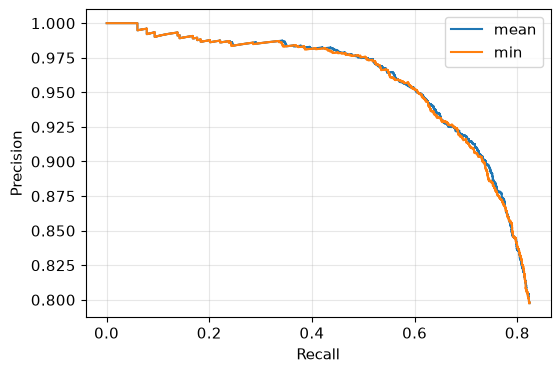

mean: порог 0.741, F1 0.8204, при пороге 0: 0.8104, прирост +1.00 п. п.
min: порог 0.629, F1 0.8211, при пороге 0: 0.8104, прирост +1.07 п. п.


In [34]:
if '6.5' in BONUS_TASKS:
    # ваш код
    predicted_tags, word_probs = predict_word_tags(model, val_tokens, return_probs=True)
    validation_gold_spans = [set(bio_to_spans(tags)) for tags in val_gold]
    gold_count = sum(map(len, validation_gold_spans))

    def span_pr(reduce_confidence):
        candidates = []
        for tags, probs, gold in zip(predicted_tags, word_probs, validation_gold_spans, strict=True):
            for span in bio_to_spans(tags):
                start, end, _ = span
                candidates.append((reduce_confidence(probs[start:end]), span in gold))
        candidates.sort(key=lambda pair: pair[0], reverse=True)

        scores = np.array([score for score, _ in candidates])
        last_in_group = np.flatnonzero(np.r_[scores[:-1] != scores[1:], True])
        true_positives = np.cumsum([hit for _, hit in candidates])[last_in_group]
        predicted_count = last_in_group + 1
        precision = true_positives / predicted_count
        recall = true_positives / gold_count
        f1 = 2 * true_positives / (gold_count + predicted_count)
        best = int(np.argmax(f1))
        return recall, precision, dict(
            threshold=float(scores[last_in_group[best]]),
            f1=float(f1[best]), f1_at_zero=float(f1[-1]),
            precision=float(precision[best]), recall=float(recall[best]),
        )

    threshold_results = {}
    plt.figure(figsize=(6, 4))
    for name, reduce_confidence in [('mean', np.mean), ('min', min)]:
        recall, precision, threshold_results[name] = span_pr(reduce_confidence)
        plt.step(recall, precision, where='post', label=name)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
    for name, scores in threshold_results.items():
        gain = 100 * (scores['f1'] - scores['f1_at_zero'])
        print(f"{name}: порог {scores['threshold']:.3f}, F1 {scores['f1']:.4f}, "
              f"при пороге 0: {scores['f1_at_zero']:.4f}, прирост {gain:+.2f} п. п.")

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Лучший порог - 0,629 по минимальной уверенности, F1 вырос с 0,8104 при нулевом пороге до 0,8211. Для среднего максимум F1 0,8204, для минимума 0,8211. Среднее сглаживает слабое слово, минимум учитывает самое слабое. Фильтр удаляет спаны, поэтому recall может только остаться прежним или снизиться.